# Modèles génératifs avec PyTorch
## Discriminatif · Autoencodeur · VAE sur MNIST

---

### Objectifs

À la fin de ce notebook, vous saurez :

- Charger et explorer le jeu de données **MNIST**.
- Construire, entraîner et **évaluer un classifieur** (modèle discriminatif $P(y|x)$).
- Construire, entraîner et **explorer un autoencodeur** (reconstruction, espace latent 2D).
- Construire, entraîner et **explorer un VAE** (échantillonnage, régularisation).
- Comprendre les **limites** d'un autoencodeur classique et pourquoi le VAE les résout.

### Plan du notebook

| Partie | Contenu |
|--------|---------|
| I | Chargement du dataset MNIST |
| II | Modèle discriminatif (classification) |
| III | Autoencodeur simple (AE) |
| IV | Variational Autoencoder (VAE) |
| V | Synthèse comparative et exercices |

### Prérequis

- Bases de PyTorch (`nn.Module`, tenseurs, autograd).
- Notions de probabilités : gaussienne, divergence KL.

## Rappel : discriminatif vs génératif

Un modèle **discriminatif** apprend la frontière entre classes :

$$
x \;\longrightarrow\; P(y \mid x)
$$

Il répond à la question « *étant donné $x$, quelle est la classe la plus probable ?* ».

Un modèle **génératif** apprend la distribution des données :

$$
P(x) \quad \text{ou} \quad P(x, y) \quad \text{ou} \quad P(x \mid z)
$$

Il peut **générer** de nouveaux échantillons $x$ qui ressemblent à ceux du dataset.

Trois familles seront abordées :

1. **Classifieur MLP** : $x \to y$, discriminatif.
2. **Autoencodeur** : $x \to z \to \hat{x}$, reconstruction, non régularisé.
3. **VAE** : $x \to (\mu, \sigma) \to z \to \hat{x}$, reconstruction + régularisation latente.

In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from torcheval.metrics import MulticlassAccuracy
from sklearn.metrics import confusion_matrix, classification_report

print("PyTorch :", torch.__version__)
print("CUDA disponible :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

PyTorch : 2.6.0
CUDA disponible : True
GPU : NVIDIA GeForce GTX 1660 Ti


In [2]:
# Make sh reporoducible
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device utilisé :", device)

# Dossiers
os.makedirs("data", exist_ok=True)
os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("outputs/checkpoints", exist_ok=True)

Device utilisé : cuda


In [ ]:
# Initialisation des transformations pour les données MNIST
def show_images(images, labels=None, n=10, title=None):
    """Affiche n images sur une ligne."""
    images = images[:n]
    fig, axes = plt.subplots(1, n, figsize=(1.5 * n, 2))
    for i, ax in enumerate(axes):
        img = images[i].cpu().squeeze().numpy()
        ax.imshow(img, cmap="gray")
        if labels is not None:
            ax.set_title(f"y = {labels[i].item()}")
        ax.axis("off")
    if title:
        plt.suptitle(title)
    plt.tight_layout()
    plt.show()


def plot_curve(values, title, ylabel="Loss", xlabel="Epoch"):
    plt.figure(figsize=(7, 4))
    plt.plot(range(1, len(values) + 1), values, marker="o")
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.grid(True, alpha=0.3)
    plt.show()

# Partie I — Jeu de données MNIST

**MNIST** est un jeu de données classique de chiffres manuscrits.

- **60 000** images d'entraînement
- **10 000** images de test
- Chaque image : $28 \times 28 = 784$ pixels, en niveaux de gris
- Labels : $y \in \{0, 1, \dots, 9\}$

### Pipeline de prétraitement

`transforms.ToTensor()` effectue deux choses :

1. Convertit l'image PIL en tenseur PyTorch.
2. Normalise les pixels dans l'intervalle $[0, 1]$.

Cette normalisation est indispensable pour le VAE, dont la sortie est une **sigmoïde** (bornée dans $[0, 1]$).

In [ ]:
# Chargement des données MNIST
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
test_dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=128, shuffle=False)

print(f"Train : {len(train_dataset)}")
print(f"Test  : {len(test_dataset)}")

100%|██████████| 9.91M/9.91M [00:02<00:00, 3.62MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 274kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 2.55MB/s]
100%|██████████| 4.54k/4.54k [00:00<?, ?B/s]

Train : 60000
Test  : 10000


Shape batch : torch.Size([128, 1, 28, 28])
Shape labels : torch.Size([128])
Min / Max pixels : 0.0 1.0


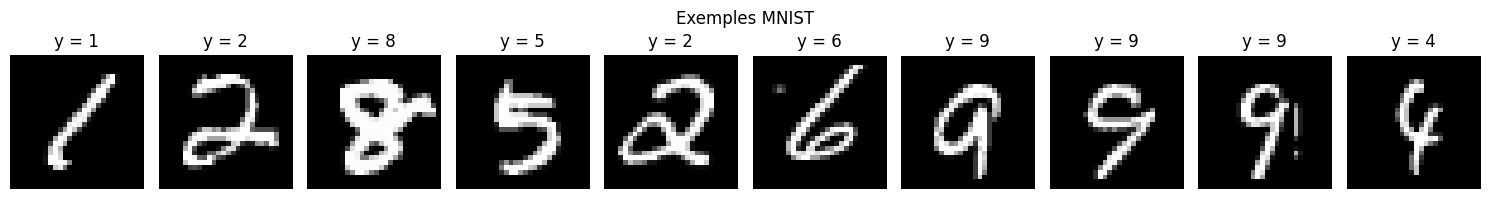

In [5]:
# Affichage d'un batch d'images
images, labels = next(iter(train_loader))

print("Shape batch :", images.shape)   # [B, 1, 28, 28]
print("Shape labels :", labels.shape)  # [B]
print("Min / Max pixels :", images.min().item(), images.max().item())

show_images(images, labels, n=10, title="Exemples MNIST")

### Interprétation

- Chaque image est un tenseur `[1, 28, 28]`.
- Les valeurs sont dans $[0, 1]$.
- Les labels sont des entiers `long` compatibles avec `CrossEntropyLoss`.
- Nous réutiliserons **ces mêmes loaders** dans toutes les parties pour garantir une comparaison équitable.

# Partie II — Modèle discriminatif

## Objectif

Apprendre une fonction qui prédit la classe à partir de l'image :

$$
x \;\longrightarrow\; \hat{y} = \arg\max_k P(y=k \mid x)
$$

## Architecture

Un **perceptron multicouche** (MLP) simple :

$$
784 \;\to\; 128 \;\to\; 10
$$

## Fonction de perte

`CrossEntropyLoss` combine un `LogSoftmax` et une `NLLLoss`.

$$
\mathcal{L}_{class} = -\log \frac{\exp(z_y)}{\sum_k \exp(z_k)}
$$

où $z$ sont les logits produits par le réseau.

> **Point clé** : ce modèle a besoin des **labels** $y$ pour apprendre. Il discrimine mais ne génère pas.

In [6]:
# Modèle de classification pour MNIST
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.net(x)


classifier = Classifier().to(device)
print(classifier)

Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [7]:
# Définition de la fonction de perte et de l'optimiseur
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)


def train_classifier(model, loader, optimizer, criterion, epochs=5):
    model.train()
    history = []
    for epoch in range(epochs):
        total_loss = 0.0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * x.size(0)

        avg = total_loss / len(loader.dataset)
        history.append(avg)
        print(f"Epoch {epoch+1}/{epochs} — Loss = {avg:.4f}")
    return history

Epoch 1/5 — Loss = 0.4116
Epoch 2/5 — Loss = 0.1943
Epoch 3/5 — Loss = 0.1375
Epoch 4/5 — Loss = 0.1058
Epoch 5/5 — Loss = 0.0853


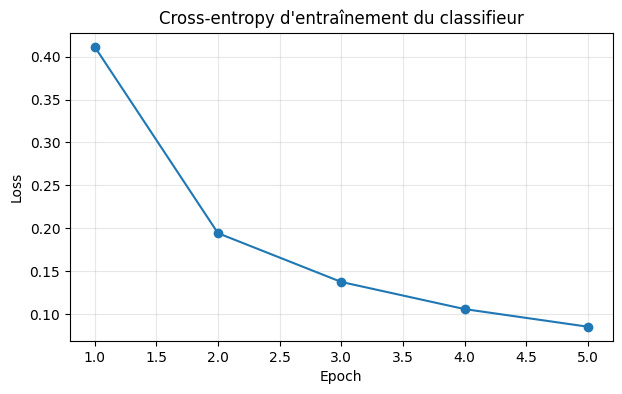

In [8]:
# Entraînement du classifieur
history_classifier = train_classifier(
    classifier, train_loader, optimizer, criterion, epochs=5
)

plot_curve(history_classifier, "Cross-entropy d'entraînement du classifieur")

In [9]:
# Évaluation du classifieur
@torch.no_grad()
def evaluate_classifier(model, loader, device):
    model.eval()
    metric = MulticlassAccuracy(device=device)
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        metric.update(logits, y)
    return metric.compute().item()


acc = evaluate_classifier(classifier, test_loader, device)
print(f"Accuracy test = {100 * acc:.2f}%")

Accuracy test = 97.25%


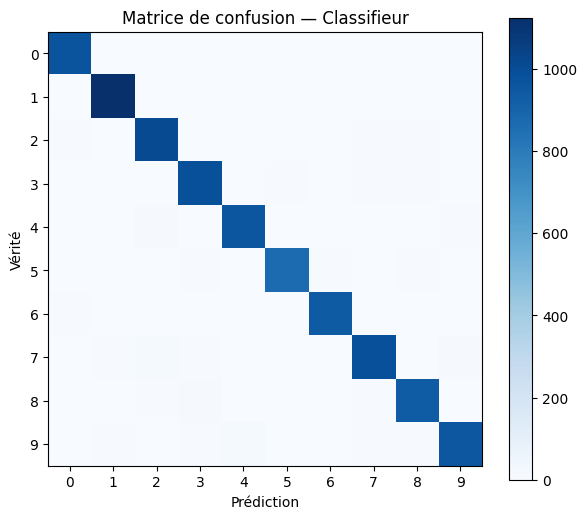

              precision    recall  f1-score   support

           0      0.980     0.989     0.984       980
           1      0.979     0.991     0.985      1135
           2      0.962     0.976     0.969      1032
           3      0.966     0.976     0.971      1010
           4      0.973     0.977     0.975       982
           5      0.980     0.972     0.976       892
           6      0.974     0.978     0.976       958
           7      0.971     0.959     0.965      1028
           8      0.962     0.960     0.961       974
           9      0.979     0.945     0.962      1009

    accuracy                          0.973     10000
   macro avg      0.973     0.972     0.972     10000
weighted avg      0.973     0.973     0.972     10000



In [10]:
# Collecter les prédictions du classifieur
@torch.no_grad()
def collect_predictions(model, loader, device):
    model.eval()
    all_preds, all_labels = [], []
    for x, y in loader:
        x = x.to(device)
        preds = model(x).argmax(dim=1).cpu()
        all_preds.append(preds)
        all_labels.append(y)
    return torch.cat(all_preds).numpy(), torch.cat(all_labels).numpy()


y_pred, y_true = collect_predictions(classifier, test_loader, device)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap="Blues")
plt.title("Matrice de confusion — Classifieur")
plt.xlabel("Prédiction")
plt.ylabel("Vérité")
plt.colorbar()
plt.xticks(range(10))
plt.yticks(range(10))
plt.show()

print(classification_report(y_true, y_pred, digits=3))

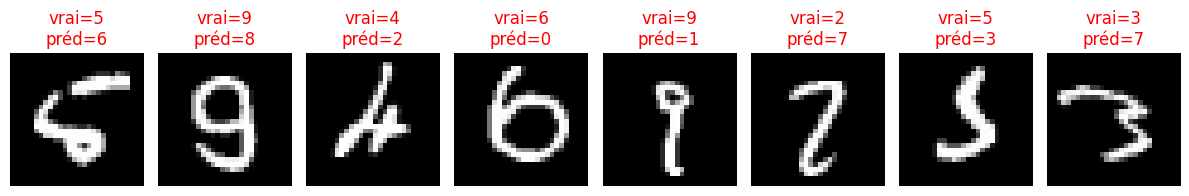

In [11]:
# Visualiser quelques erreurs du classifieur
@torch.no_grad()
def show_mistakes(model, loader, device, n=8):
    model.eval()
    errors = []
    for x, y in loader:
        x_gpu = x.to(device)
        preds = model(x_gpu).argmax(dim=1).cpu()
        mask = preds != y
        for img, p, t in zip(x[mask], preds[mask], y[mask]):
            errors.append((img, p.item(), t.item()))
        if len(errors) >= n:
            break

    fig, axes = plt.subplots(1, n, figsize=(1.5 * n, 2))
    for ax, (img, p, t) in zip(axes, errors[:n]):
        ax.imshow(img.squeeze().numpy(), cmap="gray")
        ax.set_title(f"vrai={t}\npréd={p}", color="red")
        ax.axis("off")
    plt.tight_layout()
    plt.show()


show_mistakes(classifier, test_loader, device)

### Interprétation

- Le classifieur atteint **~96-98 %** d'accuracy en quelques époques seulement.
- Les erreurs concernent principalement des chiffres mal écrits ou ambigus (4/9, 3/8, 7/1…).
- **Limite fondamentale** : ce modèle apprend $P(y \mid x)$. Il ne peut **pas** générer une nouvelle image, ni modéliser la structure des données elles-mêmes.

Pour générer des images, il faut changer de paradigme. C'est l'objet des parties suivantes.

# Partie III — Autoencodeur simple

## Idée

Un autoencodeur apprend à **reconstruire son entrée** via un goulot d'étranglement :

$$
x \;\xrightarrow{\text{Encoder}}\; z \;\xrightarrow{\text{Decoder}}\; \hat{x}
$$

- $z \in \mathbb{R}^{d}$ avec $d \ll 784$ : représentation **latente** comprimée.
- Aucun label n'est utilisé.
- Objectif : $\hat{x} \approx x$.

## Loss de reconstruction

$$
\mathcal{L}_{rec} = \frac{1}{N}\sum_{i=1}^{N} \| x_i - \hat{x}_i \|^2
$$

On utilise `MSELoss`. Le décodeur se termine par une **sigmoïde** pour rester dans $[0, 1]$.

## Choix de $d = 2$

On choisit **volontairement** $d = 2$ pour pouvoir **visualiser l'espace latent dans un plan**.

In [12]:
# Autoencodeur pour MNIST
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid(),
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        return self.decode(self.encode(x))


ae = Autoencoder(latent_dim=2).to(device)
print(ae)

Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


In [13]:
# Définition de la fonction de perte et de l'optimiseur pour l'autoencodeur
ae_criterion = nn.MSELoss()
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)


def train_autoencoder(model, loader, optimizer, criterion, epochs=20):
    model.train()
    history = []
    for epoch in range(epochs):
        total = 0.0
        for x, _ in loader:
            x = x.to(device)
            x_hat = model(x)
            loss = criterion(x_hat, x)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total += loss.item() * x.size(0)

        avg = total / len(loader.dataset)
        history.append(avg)
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"Epoch {epoch+1}/{epochs} — MSE = {avg:.5f}")
    return history

Epoch 1/20 — MSE = 0.06459
Epoch 5/20 — MSE = 0.04484
Epoch 10/20 — MSE = 0.04174
Epoch 15/20 — MSE = 0.04021
Epoch 20/20 — MSE = 0.03922


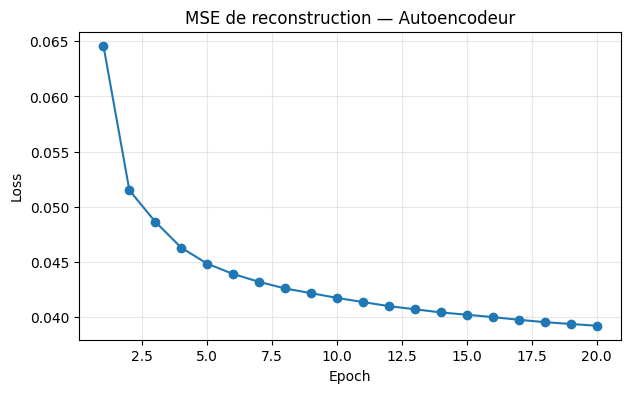

In [14]:
# Visualisation de la reconstruction par l'autoencodeur
history_ae = train_autoencoder(ae, train_loader, ae_optimizer, ae_criterion, epochs=20)
plot_curve(history_ae, "MSE de reconstruction — Autoencodeur")

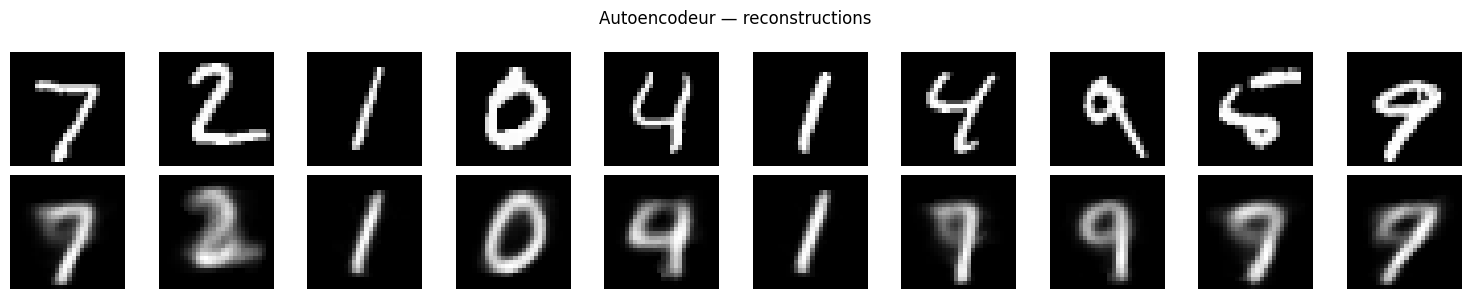

In [15]:
# Visualisation des reconstructions
ae.eval()
x, _ = next(iter(test_loader))
x = x[:10].to(device)

with torch.no_grad():
    x_hat = ae(x)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")
    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstruit")
plt.suptitle("Autoencodeur — reconstructions")
plt.tight_layout()
plt.show()

In [16]:
# Évaluation de l'autoencodeur
@torch.no_grad()
def evaluate_ae(model, loader, criterion, device):
    model.eval()
    total, n = 0.0, 0
    for x, _ in loader:
        x = x.to(device)
        x_hat = model(x)
        total += criterion(x_hat, x).item() * x.size(0)
        n += x.size(0)
    return total / n


mse_test = evaluate_ae(ae, test_loader, ae_criterion, device)
print(f"MSE test = {mse_test:.5f}")

MSE test = 0.03954


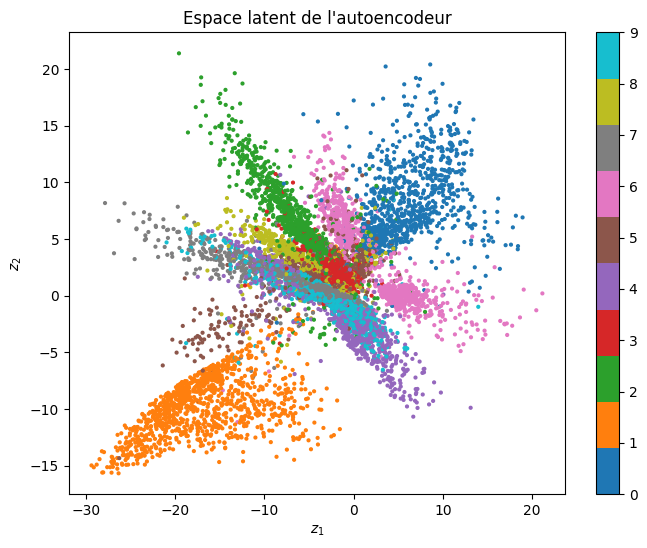

In [17]:
# Visualisation de l'espace latent
@torch.no_grad()
def encode_dataset(model, loader, mode="ae", device=device):
    model.eval()
    Z, Y = [], []
    for x, y in loader:
        x = x.to(device)
        if mode == "ae":
            z = model.encode(x)
        else:
            mu, _ = model.encode(x)
            z = mu
        Z.append(z.cpu())
        Y.append(y)
    return torch.cat(Z).numpy(), torch.cat(Y).numpy()


Z_ae, Y_ae = encode_dataset(ae, test_loader, mode="ae")

plt.figure(figsize=(8, 6))
sc = plt.scatter(Z_ae[:, 0], Z_ae[:, 1], c=Y_ae, s=4, cmap="tab10")
plt.xlabel("$z_1$"); plt.ylabel("$z_2$")
plt.title("Espace latent de l'autoencodeur")
plt.colorbar(sc, ticks=range(10))
plt.show()

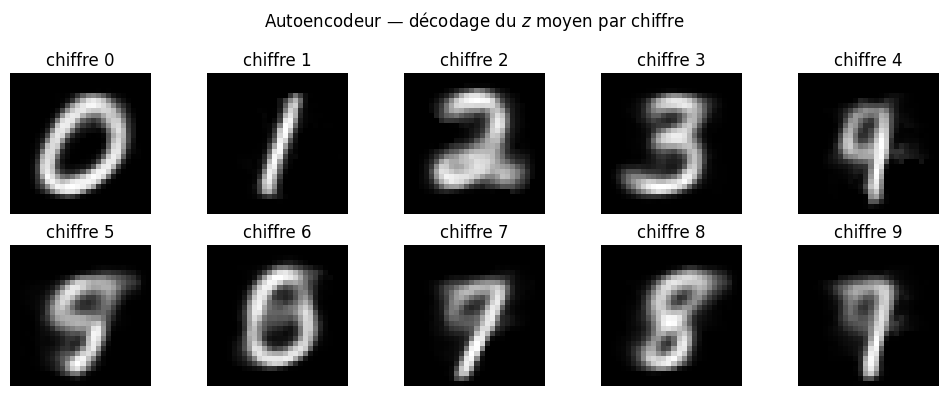

In [18]:
# Visualisation du $z$ moyen par chiffre
@torch.no_grad()
def generate_mean_digit(model, loader, digit, mode="ae", device=device):
    model.eval()
    sum_z, n = None, 0
    for x, y in loader:
        x = x[y == digit].to(device)
        if x.shape[0] == 0:
            continue
        z = model.encode(x) if mode == "ae" else model.encode(x)[0]
        sum_z = z.sum(0, keepdim=True) if sum_z is None else sum_z + z.sum(0, keepdim=True)
        n += z.shape[0]
    z_mean = sum_z / n
    return model.decode(z_mean).cpu(), z_mean.cpu()


fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, d in enumerate(range(10)):
    img, _ = generate_mean_digit(ae, train_loader, d, mode="ae")
    axes[i // 5, i % 5].imshow(img.squeeze(), cmap="gray")
    axes[i // 5, i % 5].set_title(f"chiffre {d}")
    axes[i // 5, i % 5].axis("off")
plt.suptitle("Autoencodeur — décodage du $z$ moyen par chiffre")
plt.tight_layout()
plt.show()

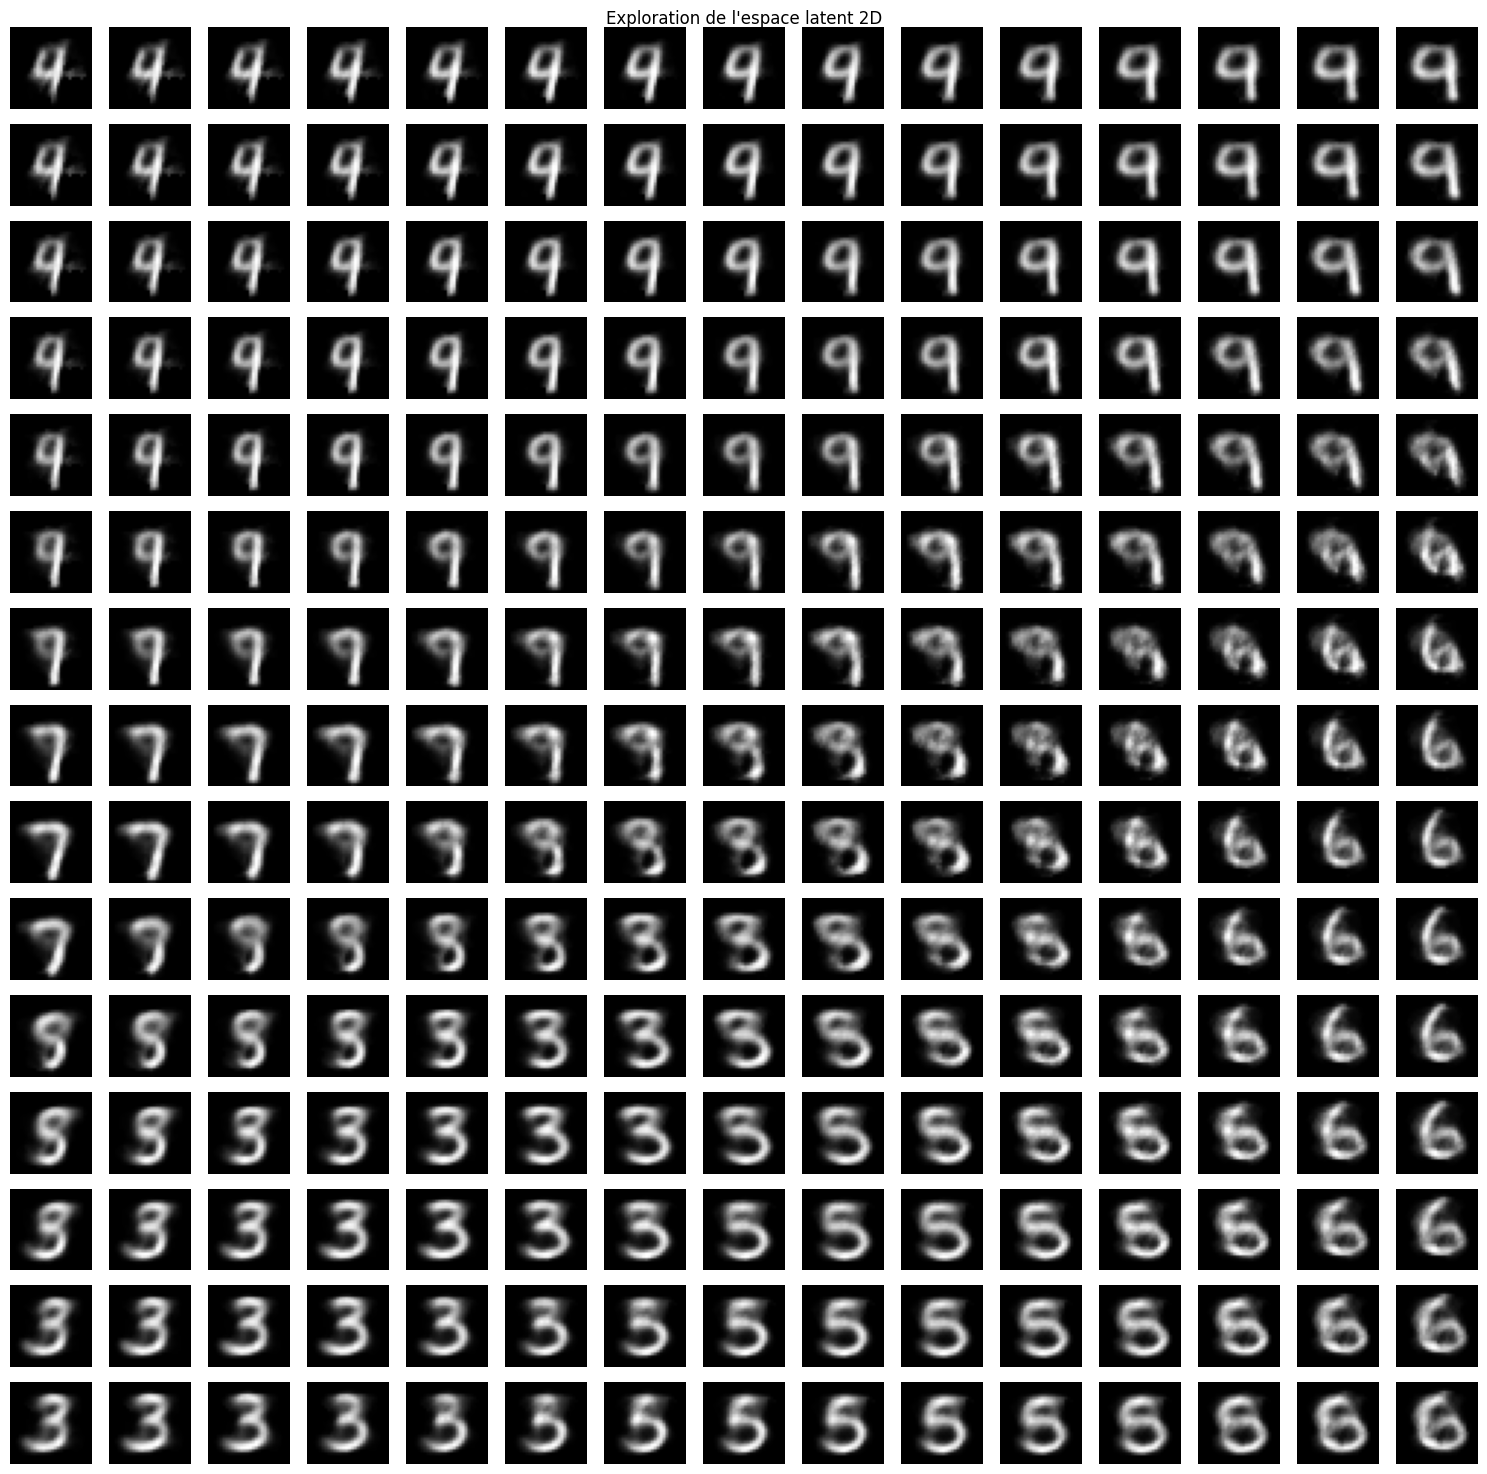

In [19]:
# Exploration de l'espace latent 2D
@torch.no_grad()
def plot_latent_grid(model, n=15, span=2.5, mode="ae", device=device):
    model.eval()
    grid_x = np.linspace(-span, span, n)
    grid_y = np.linspace(-span, span, n)
    fig, axes = plt.subplots(n, n, figsize=(n, n))
    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):
            z = torch.tensor([[xi, yi]], dtype=torch.float32).to(device)
            x_hat = model.decode(z).cpu().squeeze().numpy()
            axes[i, j].imshow(x_hat, cmap="gray")
            axes[i, j].axis("off")
    plt.suptitle("Exploration de l'espace latent 2D")
    plt.tight_layout()
    plt.show()


plot_latent_grid(ae, n=15, span=2.5)

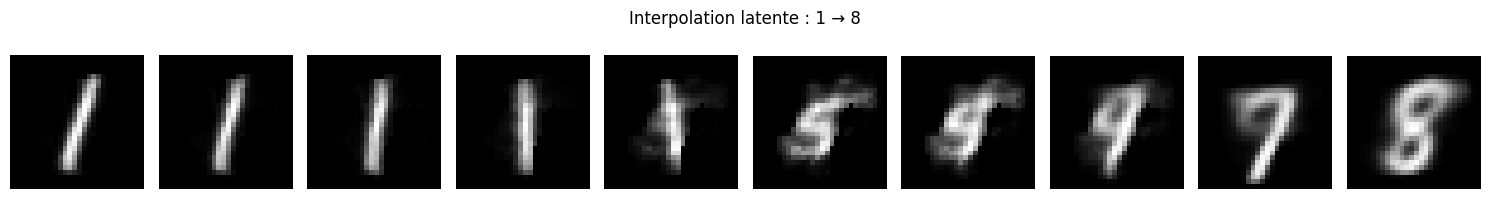

In [20]:
# Interpolation latente entre deux chiffres
@torch.no_grad()
def interpolate(model, loader, digit_a, digit_b, steps=10, mode="ae", device=device):
    model.eval()
    _, z_a = generate_mean_digit(model, loader, digit_a, mode=mode)
    _, z_b = generate_mean_digit(model, loader, digit_b, mode=mode)
    z_a, z_b = z_a.to(device), z_b.to(device)

    alphas = torch.linspace(0, 1, steps).to(device)
    images = []
    for a in alphas:
        z = (1 - a) * z_a + a * z_b
        images.append(model.decode(z).cpu().squeeze())

    fig, axes = plt.subplots(1, steps, figsize=(1.5 * steps, 2))
    for ax, img in zip(axes, images):
        ax.imshow(img, cmap="gray")
        ax.axis("off")
    plt.suptitle(f"Interpolation latente : {digit_a} → {digit_b}")
    plt.tight_layout()
    plt.show()


interpolate(ae, train_loader, digit_a=1, digit_b=8, steps=10, mode="ae")

### Interprétation et limites de l'autoencodeur

- L'AE reconstruit correctement les chiffres.
- L'espace latent 2D **colore** partiellement les classes : les chiffres similaires se regroupent.
- **Cependant** :
  - L'espace latent n'est **pas régulier** : on observe des zones "trous" sans données.
  - Si on échantillonne un $z \sim \mathcal{N}(0, I)$ au hasard, le décodeur produit souvent du **bruit** ou des images peu réalistes.
  - Rien ne contraint la distribution de $z$ à ressembler à une loi connue.
  - Les reconstructions sont plus floues que la réalité (perte d'information due à la compression).

> C'est précisément cette **absence de régularisation** qui motive le VAE.

# Partie IV — Variational Autoencoder (VAE)

## Principe

Au lieu d'associer une entrée $x$ à un **point** latent $z$, le VAE associe $x$ à une **distribution** :

$$
q(z \mid x) = \mathcal{N}(\mu(x), \sigma^2(x))
$$

L'encodeur produit deux vecteurs : $\mu(x)$ et $\log \sigma^2(x)$.

## Reparameterization trick

Pour pouvoir rétropropager à travers l'échantillonnage $z \sim \mathcal{N}(\mu, \sigma^2)$, on écrit :

$$
\epsilon \sim \mathcal{N}(0, I), \qquad
\boxed{\; z = \mu + \sigma \odot \epsilon \;}
$$

Le gradient passe alors à travers $\mu$ et $\sigma$.

## Loss VAE

Deux termes s'additionnent :

1. **Reconstruction** : $\mathcal{L}_{rec}$ (BCE, car sortie dans $[0,1]$).
2. **Régularisation KL** : la distribution latente doit rester proche d'une gaussienne standard :

$$
D_{KL}\big(q(z \mid x) \;\|\; \mathcal{N}(0, I)\big) = -\frac{1}{2} \sum_j \big( 1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2 \big)
$$

Loss totale :

$$
\boxed{\;\mathcal{L}_{VAE} = \mathcal{L}_{rec} + \beta \, D_{KL}\;}
$$

Le paramètre $\beta$ (typiquement $1$) permet de doser régularisation vs fidélité.

In [21]:
# Variational Autoencoder (VAE) pour MNIST
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU(),
        )
        self.fc_mu     = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid(),
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z)
        return x_hat, mu, logvar


vae = VAE(latent_dim=2).to(device)
print(vae)

VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (fc_mu): Linear(in_features=64, out_features=2, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


In [22]:
# Définition de la fonction de perte et de l'optimiseur pour le VAE
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    # Reconstruction : somme sur tous les pixels, moyennée ensuite
    rec = F.binary_cross_entropy(x_hat, x, reduction="sum")
    # KL : formule fermée pour gaussienne diagonale
    kl  = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return rec + beta * kl, rec, kl

In [23]:
# Training the VAE
vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)


def train_vae(model, loader, optimizer, epochs=30, beta=1.0):
    model.train()
    hist = {"loss": [], "rec": [], "kl": []}
    for epoch in range(epochs):
        total_loss = total_rec = total_kl = 0.0
        for x, _ in loader:
            x = x.to(device)
            x_hat, mu, logvar = model(x)
            loss, rec, kl = vae_loss(x_hat, x, mu, logvar, beta=beta)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            total_rec  += rec.item()
            total_kl   += kl.item()

        n = len(loader.dataset)
        hist["loss"].append(total_loss / n)
        hist["rec"].append(total_rec / n)
        hist["kl"].append(total_kl / n)

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(
                f"Epoch {epoch+1:3d}/{epochs} | "
                f"Loss={hist['loss'][-1]:7.2f} | "
                f"Rec={hist['rec'][-1]:7.2f} | "
                f"KL={hist['kl'][-1]:5.2f}"
            )
    return hist

In [24]:
# Entraînement du VAE
history_vae = train_vae(vae, train_loader, vae_optimizer, epochs=30, beta=1.0)

Epoch   1/30 | Loss= 194.41 | Rec= 190.32 | KL= 4.09
Epoch   5/30 | Loss= 154.28 | Rec= 148.57 | KL= 5.71
Epoch  10/30 | Loss= 147.59 | Rec= 141.49 | KL= 6.10
Epoch  15/30 | Loss= 144.34 | Rec= 138.01 | KL= 6.33
Epoch  20/30 | Loss= 142.45 | Rec= 135.99 | KL= 6.45
Epoch  25/30 | Loss= 141.26 | Rec= 134.71 | KL= 6.55
Epoch  30/30 | Loss= 140.51 | Rec= 133.91 | KL= 6.59


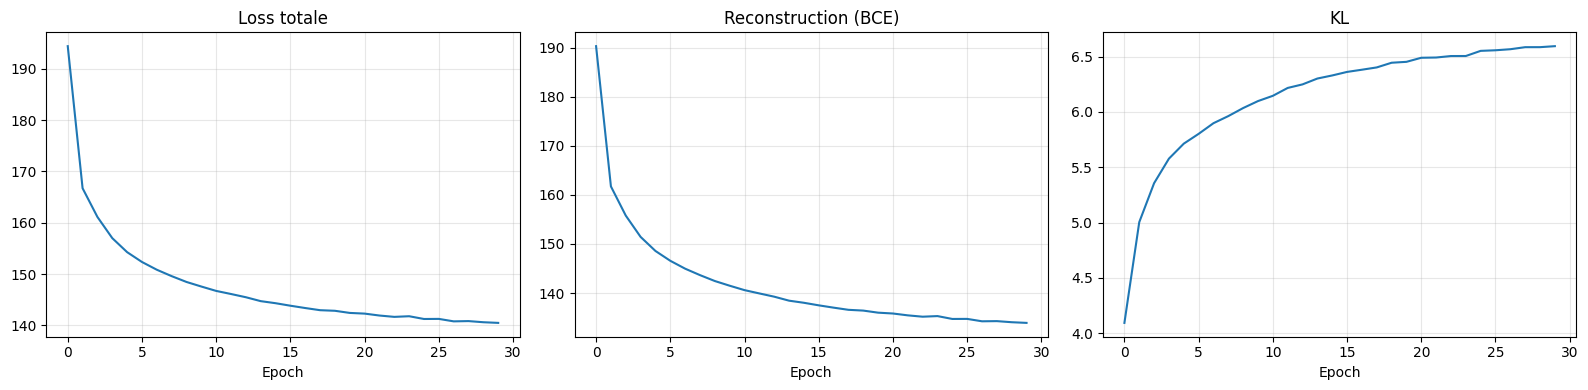

In [25]:
# Visualisation des courbes de perte du VAE
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(history_vae["loss"]); axes[0].set_title("Loss totale")
axes[1].plot(history_vae["rec"]);  axes[1].set_title("Reconstruction (BCE)")
axes[2].plot(history_vae["kl"]);   axes[2].set_title("KL")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

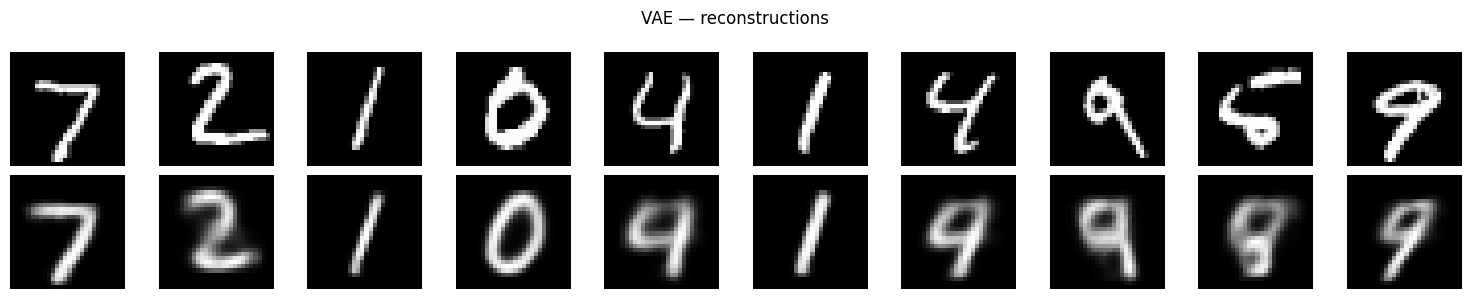

In [26]:
# Visualisation des reconstructions du VAE
vae.eval()
x, _ = next(iter(test_loader))
x = x[:10].to(device)

with torch.no_grad():
    x_hat, _, _ = vae(x)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray"); axes[1, i].axis("off")
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("VAE")
plt.suptitle("VAE — reconstructions")
plt.tight_layout()
plt.show()

In [27]:
# Évaluation du VAE
@torch.no_grad()
def evaluate_vae(model, loader, beta=1.0):
    model.eval()
    tot_loss = tot_rec = tot_kl = 0.0
    for x, _ in loader:
        x = x.to(device)
        x_hat, mu, logvar = model(x)
        loss, rec, kl = vae_loss(x_hat, x, mu, logvar, beta=beta)
        tot_loss += loss.item(); tot_rec += rec.item(); tot_kl += kl.item()
    n = len(loader.dataset)
    return tot_loss/n, tot_rec/n, tot_kl/n


loss_t, rec_t, kl_t = evaluate_vae(vae, test_loader)
print(f"Test — Loss={loss_t:.2f} | Rec={rec_t:.2f} | KL={kl_t:.2f}")
print(f"ELBO (≈ -Loss) = {-loss_t:.2f}")

Test — Loss=141.52 | Rec=134.75 | KL=6.77
ELBO (≈ -Loss) = -141.52


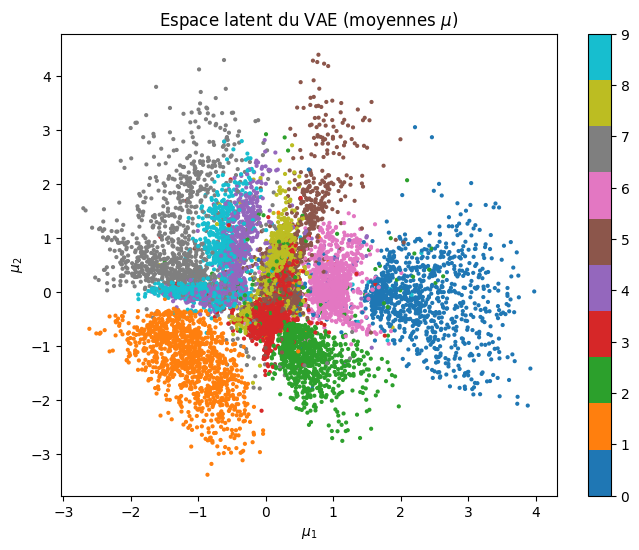

In [28]:
# Visualisation de l'espace latent du VAE
MU_vae, Y_vae = encode_dataset(vae, test_loader, mode="vae")

plt.figure(figsize=(8, 6))
sc = plt.scatter(MU_vae[:, 0], MU_vae[:, 1], c=Y_vae, s=4, cmap="tab10")
plt.xlabel("$\\mu_1$"); plt.ylabel("$\\mu_2$")
plt.title("Espace latent du VAE (moyennes $\\mu$)")
plt.colorbar(sc, ticks=range(10))
plt.show()

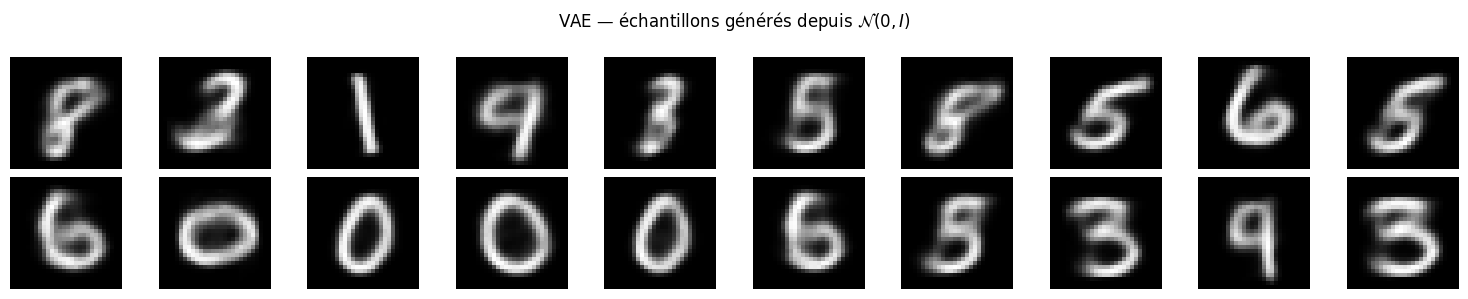

In [29]:
# Génération aléatoire à partir de z ~ N(0, I)
vae.eval()
with torch.no_grad():
    z = torch.randn(20, 2).to(device)
    samples = vae.decode(z).cpu()

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i].squeeze(), cmap="gray")
    ax.axis("off")
plt.suptitle("VAE — échantillons générés depuis $\\mathcal{N}(0, I)$")
plt.tight_layout()
plt.show()

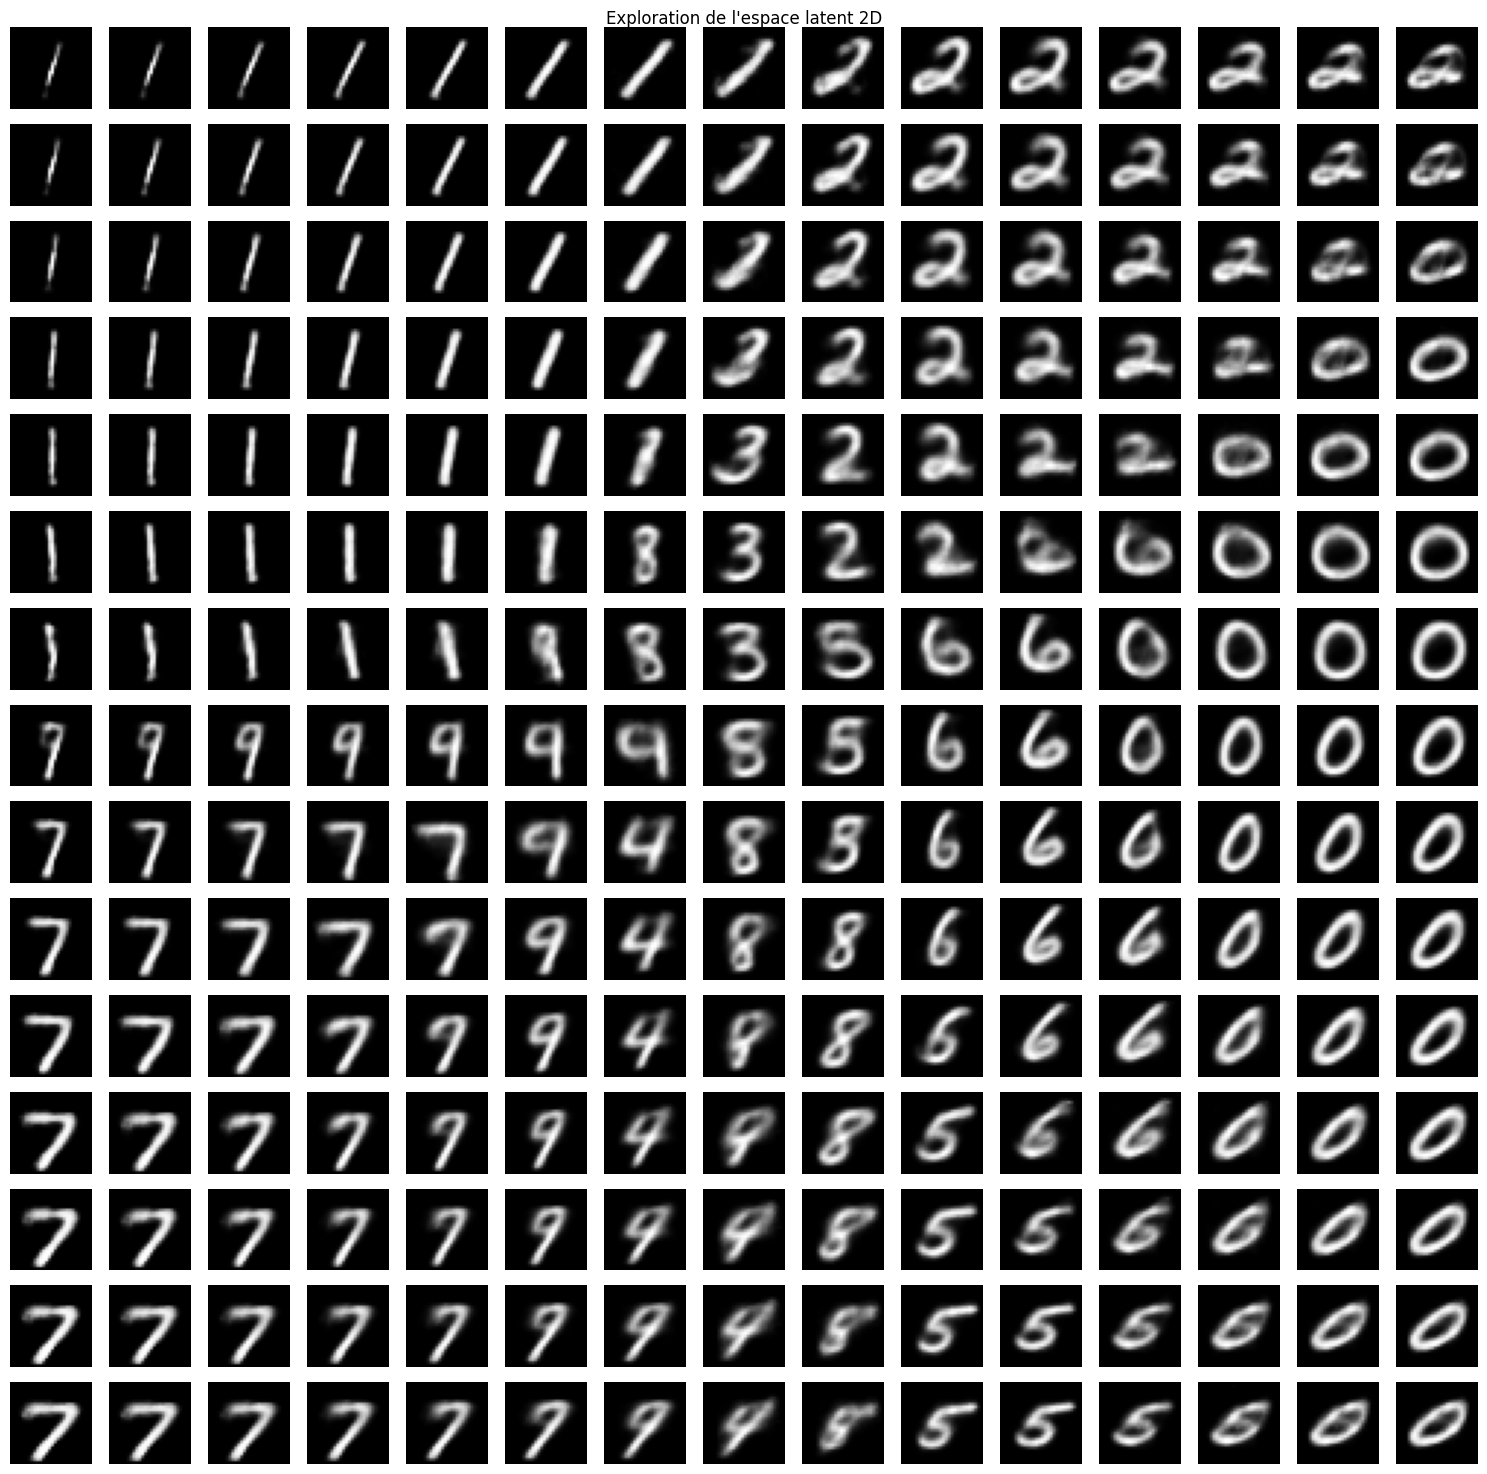

In [30]:
# Exploration de l'espace latent 2D du VAE
plot_latent_grid(vae, n=15, span=2.5)

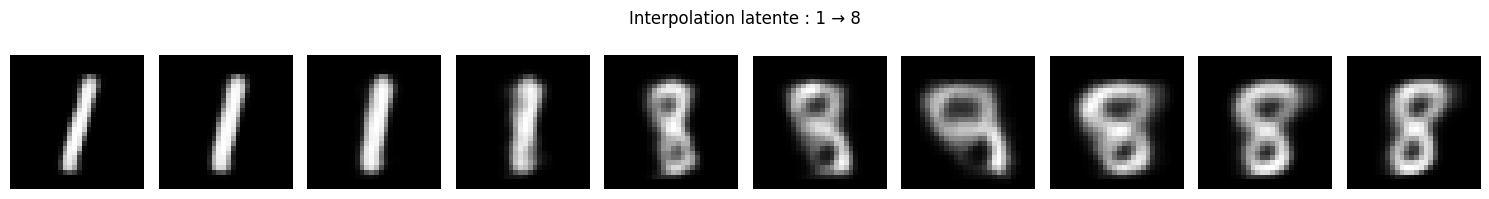

In [31]:
# Interpolation latente entre deux chiffres avec le VAE
interpolate(vae, train_loader, digit_a=1, digit_b=8, steps=10, mode="vae")

### Interprétation du VAE

- L'espace latent est **continu** et **régulier** : les classes se regroupent proprement autour de l'origine.
- Les échantillons tirés de $z \sim \mathcal{N}(0, I)$ sont **des chiffres plausibles**, contrairement à l'AE.
- Les interpolations linéaires entre deux chiffres produisent des formes intermédiaires cohérentes.
- La loss KL **forces** la distribution latente à ressembler à une gaussienne standard.

### Compromis clé

- Plus $\beta \uparrow$ : espace latent plus régulier mais reconstructions plus floues.
- Plus $\beta \downarrow$ : reconstructions plus nettes mais espace latent moins lisse.
- $\beta = 1$ est la valeur d'origine du VAE (Kingma & Welling, 2013).

# Partie V — Synthèse comparative

## Tableau récapitulatif

| Modèle | Objectif | Labels ? | Génération | Loss |
|---|---|---|---|---|
| **Classifieur** | $P(y \mid x)$ | Oui | Non | CrossEntropy |
| **Autoencodeur** | $x \to \hat{x}$ | Non | Difficile | MSE / BCE |
| **VAE** | $\hat{x}$ + régularisation de $q(z\mid x)$ | Non | Oui | BCE + KL |

## Ce qu'il faut retenir

1. **Discriminatif vs génératif** : le premier apprend à décider, le second apprend à modéliser.
2. **AE** : compresse, mais ne régularise pas → l'espace latent contient des trous.
3. **VAE** : ajoute une **contrainte probabiliste** → échantillonnable et interpolable.
4. Le VAE est **plus dur à entraîner** (compromis reconstruction/KL) mais **génère** réellement.

## Pistes d'approfondissement

- VAE **conditionnel** (cVAE) : conditionner sur $y$ pour contrôler le chiffre généré.
- VAE avec **convolutions** (DC-VAE) pour des images plus nettes.
- **β-VAE** : découplage des facteurs latents en augmentant $\beta$.
- **Normalizing flows** ou **diffusion models** : alternatives modernes aux VAEs.

## Exercices proposés

1. **Classifieur** : remplacer le MLP par un petit CNN. Observer l'accuracy finale.
2. **Autoencodeur** : tester `latent_dim ∈ {2, 8, 32}`. Comment évolue la reconstruction ?
3. **Autoencodeur** : visualiser l'erreur de reconstruction pour chaque chiffre.
4. **VAE** : entraîner avec `beta ∈ {0.1, 1, 4}`. Comparer :
   - la netteté des reconstructions,
   - la régularité de l'espace latent,
   - la qualité des échantillons générés.
5. **VAE conditionnel** : injecter le label $y$ dans l'encodeur et le décodeur pour choisir le chiffre généré.
6. **Comparaison** : calculer une FID approximative (features extraites d'un classifieur pré-entraîné) pour AE vs VAE.
7. **Bonus** : implémenter un `ConvVAE` et comparer visuellement sur les mêmes échantillons.

---

## Références

- Kingma & Welling, *Auto-Encoding Variational Bayes*, ICLR 2014.
- Goodfellow et al., *Deep Learning*, chapitre 20 (Deep Generative Models).
- PyTorch — `torch.nn`, `torch.optim`, `torchvision`.